# 03 · Cadenas de Markov aplicadas a la mora

**Descargo metodológico:** los estados describen niveles del indicador y sus transiciones estimadas. No son una clasificación regulatoria ni una predicción de quiebra.

Se estudia la matriz de transición entre cuatro estados de mora, la distribución estacionaria, los tiempos de permanencia y las probabilidades de alcanzar el estado Crítica a distintos horizontes.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def raiz_proyecto():
    actual = Path.cwd()
    for base in [actual, *actual.parents]:
        if (base / "dashboard" / "data.json").exists():
            return base
    raise FileNotFoundError("Ejecute el notebook desde el repositorio del proyecto")

ROOT = raiz_proyecto()
datos = json.loads((ROOT / "dashboard" / "data.json").read_text(encoding="utf-8"))
BANCO = "bfort"
INDICADOR = "mora"
banco = next(b for b in datos["bancos"] if b["id"] == BANCO)
meta_indicador = next(i for i in datos["indicadores_meta"] if i["id"] == INDICADOR)
serie = datos["series"][BANCO][INDICADOR]
tabla = pd.DataFrame({
    "fecha": pd.to_datetime(serie["fechas"]),
    "valor": serie["observado"],
}).set_index("fecha")
tabla.head()

,valor
fecha,
2019-01-01,1.668071
2019-02-01,2.277313
2019-03-01,2.143988
2019-04-01,2.250342
2019-05-01,1.905817


## Estados y matriz de transición

In [2]:
estados = datos["markov"]["estados"]
m = datos["markov"]["por_banco"][BANCO]
P = np.array(m["matriz_transicion"], dtype=float)
tabla_p = pd.DataFrame(P, index=estados, columns=estados)
tabla_p.round(4)

,Baja,Media,Alta,Crítica
Baja,0.6998,0.3000,0.0001,0.0001
Media,0.0968,0.8709,0.0323,0.0000
Alta,0.0001,0.0001,0.9332,0.0667
Crítica,0.0000,0.0000,0.0000,0.9999


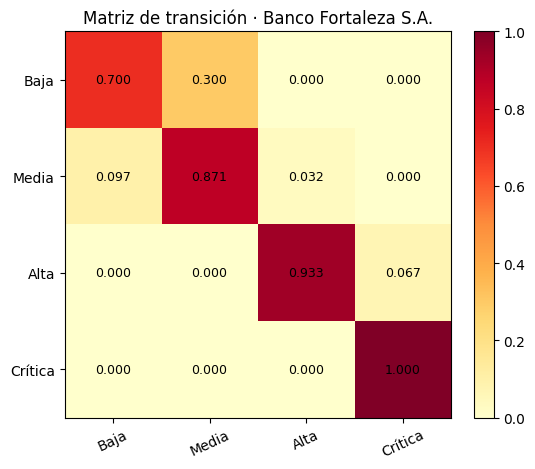

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
imagen = ax.imshow(P, cmap="YlOrRd", vmin=0, vmax=1)
for i in range(P.shape[0]):
    for j in range(P.shape[1]):
        ax.text(j, i, f"{P[i, j]:.3f}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(len(estados)), estados, rotation=25)
ax.set_yticks(range(len(estados)), estados)
ax.set_title(f"Matriz de transición · {banco['nombre']}")
plt.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## Distribución estacionaria y permanencia

In [4]:
resumen = pd.DataFrame({
    "Estado": estados,
    "π estacionaria": m["dist_estacionaria"],
    "Permanencia media (meses)": m["tiempo_permanencia_meses"],
})
resumen

,Estado,π estacionaria,Permanencia media (meses)
0,Baja,0.000859,3.331335
1,Media,0.002282,7.745191
2,Alta,0.001655,14.959123
3,Crítica,0.995204,9001.333333


## Potencias de la matriz de transición

In [5]:
for h in [1, 3, 6, 12]:
    Ph = np.linalg.matrix_power(P, h)
    print(f"Horizonte {h} meses · P(Crítica desde {estados[m['estado_actual']]}): {Ph[m['estado_actual'], 3]:.4f}")

pd.DataFrame(np.linalg.matrix_power(P, 12), index=estados, columns=estados).round(4)

Horizonte 1 meses · P(Crítica desde Crítica): 0.9999
Horizonte 3 meses · P(Crítica desde Crítica): 0.9997
Horizonte 6 meses · P(Crítica desde Crítica): 0.9994
Horizonte 12 meses · P(Crítica desde Crítica): 0.9988


,Baja,Media,Alta,Crítica
Baja,0.2075,0.5864,0.1522,0.0539
Media,0.1893,0.5419,0.1814,0.0874
Alta,0.0004,0.0008,0.4362,0.5626
Crítica,0.0002,0.0005,0.0004,0.9988


## Comparación entre bancos

In [6]:
filas = []
for clave, valor in datos["markov"]["por_banco"].items():
    filas.append({
        "banco": clave,
        "estado_actual": estados[valor["estado_actual"]],
        "pi_critica": valor["dist_estacionaria"][3],
        "p_critica_3m": valor["prob_critico_h"]["m3"],
        "p_orden_1_vs_2": valor["test_orden_1_vs_2_pval"],
    })
pd.DataFrame(filas).sort_values("p_critica_3m", ascending=False).round(4)

,banco,estado_actual,pi_critica,p_critica_3m,p_orden_1_vs_2
10,bfort,Crítica,0.9952,0.9997,1.0000
0,bisa,Alta,0.2099,0.1410,0.9970
1,bnb,Alta,0.0927,0.1099,0.9840
3,bme,Alta,0.0895,0.0880,0.9998
7,bsol,Media,0.0001,0.0001,1.0000
9,bfie,Alta,0.0000,0.0001,0.9994
6,bec,Alta,0.0000,0.0000,0.9996
5,bga,Media,0.0000,0.0000,1.0000
4,bcr,Alta,0.0000,0.0000,0.9998
8,bna,Baja,0.0000,0.0000,1.0000


## Lectura para la defensa

- Cada fila de la matriz suma uno; se usa suavizado de Laplace para evitar probabilidades nulas.
- La distribución estacionaria responde a una pregunta de largo plazo, no al próximo mes.
- Un banco con mora estructuralmente alta puede tener una probabilidad de permanencia en Crítica más informativa que una transición puntual.